# 03 · Backlog and root-cause diagnosis

**Data:** **[REAL]** the 2023 ticket export (2,330 tickets, snapshot 2024-01-04 05:39) for
every test in sections 1-6. **[SYNTHETIC]** the 20× planning scenario only in section 7
(hourly queue simulation), marked as such.

*Part of the Support SLA & Capacity Review (full story: `reports/report.html`). Inputs are rebuilt by
`python run.py`; this notebook re-runs top to bottom with `make notebooks`.*

In [1]:
import json, pandas as pd, plotly.io as pio
pio.renderers.default = "notebook_connected+png"     # interactive in HTML export, static PNG fallback for GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 1000, None
from support_ops import charts as C
from support_ops.data import load_processed, load_tickets
from support_ops.config import load_config, REPO_ROOT
kn = json.load(open(REPO_ROOT / "reports" / "key_numbers.json"))
cfg = load_config()

# --- also used in this notebook ----------------------------------------------
import numpy as np
from scipy import stats
from support_ops import kpis, rca, synth
from support_ops.sql import connect, run_sql_file
goal, aged_days = cfg["sla"]["goal_attainment"], cfg["sla"]["aged_backlog_days"]
pd.set_option("display.max_colwidth", 120)

## TL;DR

- **Not volume, not mix.** **[REAL]** A shift-share split of the Q1 → Q4 fall in resolution SLA gives
  -0.28 points to the channel mix and
  -12.65 points to performance within channels (by topic:
  +0.10 vs -13.04).
- **No capacity signal in the ticket data.** **[REAL]** Breach rates are flat across workload quintiles
  (trend-test p from 0.277 to 0.901), and
  breaches do not differ by hour of day (p = 0.42), day of week
  (p = 0.299) or weekday vs weekend (p = 0.765).
  Active work stayed flat at 15.1 tickets on average (max
  26), in line with Little's law (15.4).
  **The data shows a process change, not a capacity shortfall.** A capacity change outside the ticket data
  (time diverted to other work, tooling) cannot be excluded.
- **What changed: a new slow path.** **[REAL]** Tickets resolved late rose from
  9.8% of all tickets in H1 to 21.8%
  in H2, building gradually from 2023-03 to 2023-10 (largest single step
  around 2023-07). The never-resolved share fell
  (19.6% → 16.3%), so part of the
  late rise may be tickets that previously went stale and now close late.
- **A constant stale backlog.** **[REAL]** 418 tickets
  (17.9%) were never resolved. They are
  53.3% of all resolution breaches, with a median age of
  202 days at the snapshot; the open backlog grows all year only
  because of them.
- **Volume spike or staffing gap?** **[SYNTHETIC]** In the 20× planning scenario the queue
  builds at weekends, when arrivals are *lower*, under today's assumed weekday-weighted roster, which is short in
  30 of 168 hours, all at weekends. That is a staffing-pattern gap,
  not a volume spike. The workload-matched roster closes it (contacts reaching an agent within target
  97.9% → 99.8%),
  provided today's real roster is weekday-weighted and weekend follow-ups are done when they arise.

In [2]:
# Every number in the TL;DR above, read from reports/key_numbers.json
tldr = {
    'Q1->Q4 resolution SLA: channel-mix effect (pts)': f"{kn['rca_mix_effect_q1_q4_channel_pp']:+.2f}",
    'Q1->Q4 resolution SLA: within-channel effect (pts)': f"{kn['rca_rate_effect_q1_q4_channel_pp']:+.2f}",
    'Q1->Q4 resolution SLA: topic-mix effect (pts)': f"{kn['rca_mix_effect_q1_q4_topic_pp']:+.2f}",
    'Q1->Q4 resolution SLA: within-topic effect (pts)': f"{kn['rca_rate_effect_q1_q4_topic_pp']:+.2f}",
    'Workload-trend tests, lowest p': f"{kn['rca_load_trend_p_min']}",
    'Workload-trend tests, highest p': f"{kn['rca_load_trend_p_max']}",
    'Hour of day vs response SLA, p': f"{kn['rca_hour_of_day_p_response']}",
    'Day of week vs response SLA, p': f"{kn['rca_day_of_week_p_response']}",
    'Weekday vs weekend, response SLA, p': f"{kn['rca_weekend_p_response']}",
    'Active backlog, daily mean (tickets)': f"{kn['active_backlog_mean']:.1f}",
    'Active backlog, max (tickets)': f"{kn['active_backlog_max']}",
    "Active backlog by Little's law (tickets)": f"{kn['active_backlog_littles_law']:.1f}",
    'Resolved late, share of all tickets, H1': f"{kn['rca_late_share_h1']:.1%}",
    'Resolved late, share of all tickets, H2': f"{kn['rca_late_share_h2']:.1%}",
    'Gradual rise from': kn['rca_ramp_start'],
    'Gradual rise until': kn['rca_ramp_end'],
    'Largest single step around': kn['rca_step_month_late_share'],
    'Never resolved, share of tickets, H1': f"{kn['rca_never_share_h1']:.1%}",
    'Never resolved, share of tickets, H2': f"{kn['rca_never_share_h2']:.1%}",
    'Never-resolved tickets': f"{kn['stale_never_resolved']}",
    'Never resolved, share of all tickets': f"{kn['stale_share_of_tickets']:.1%}",
    'Never resolved, share of resolution breaches': f"{kn['stale_share_of_resolution_breaches']:.1%}",
    'Never resolved, median age at snapshot (days)': f"{kn['stale_median_age_days']:.0f}",
    "[SYNTHETIC] hours short, today's assumed roster": f"{kn['staff_hours_under_today_by_day']} of 168",
    "[SYNTHETIC] reach an agent in target, today's": f"{kn['staff_queue_sl_today_by_day']:.1%}",
    '[SYNTHETIC] reach an agent in target, matched': f"{kn['staff_queue_sl_proposed']:.1%}",
}
for label, value in tldr.items():
    print(f"{label:<53}{value}")

Q1->Q4 resolution SLA: channel-mix effect (pts)      -0.28
Q1->Q4 resolution SLA: within-channel effect (pts)   -12.65
Q1->Q4 resolution SLA: topic-mix effect (pts)        +0.10
Q1->Q4 resolution SLA: within-topic effect (pts)     -13.04
Workload-trend tests, lowest p                       0.277
Workload-trend tests, highest p                      0.901
Hour of day vs response SLA, p                       0.42
Day of week vs response SLA, p                       0.299
Weekday vs weekend, response SLA, p                  0.765
Active backlog, daily mean (tickets)                 15.1
Active backlog, max (tickets)                        26
Active backlog by Little's law (tickets)             15.4
Resolved late, share of all tickets, H1              9.8%
Resolved late, share of all tickets, H2              21.8%
Gradual rise from                                    2023-03
Gradual rise until                                   2023-10
Largest single step around                           2023

## Question

The team says it is short-staffed. Before a headcount request, the Director needs to know whether the data
shows a capacity problem (**Q4** in `docs/01_request_and_scope.md`) and, if not, what did change:

- Is the SLA fall explained by **volume or mix**? (the formal test behind notebook 01)
- Is there evidence that **load drives breaches**? Do busy days or hours show worse SLA?
- Does the backlog build from **arrival spikes or from low throughput**?
- If none of these: **what changed**, and when?

## Data

| table | built by | data | one row per |
|---|---|---|---|
| `fct_tickets` | `sql/00_fct_tickets.sql` | **[REAL]** | ticket |
| `kpi_backlog_daily` | `sql/04_backlog_daily.sql` | **[REAL]** | day, first creation date to snapshot date |
| `kpi_rca_decomposition` | `sql/08_rca_decomposition.sql` | **[REAL]** | SLA × comparison × dimension × segment |
| `kpi_load_vs_sla` | `sql/09_load_vs_sla.sql` | **[REAL]** | day with tickets |
| `rca_load_vs_sla`, `rca_time_slots`, `rca_resolution_composition` | `support_ops.rca` | **[REAL]** | quintile / test / month |
| `staff_sim_hourly` | `support_ops.staffing.capacity_plan()` → `simulate_roster()` (`support_ops.simulation.run_roster`) | **[SYNTHETIC]** | roster × simulated hour |
| `staff_demand`, `staff_coverage`, `staff_sim_summary` | `support_ops.staffing.capacity_plan()` | **[SYNTHETIC]** | hour of week / roster |
| `synth_tickets`, `synth_work_items` | `support_ops.synth.generate_tickets()`, `build_work_items()` | **[SYNTHETIC]** | ticket / agent touch |

The synthetic tables are cached outputs of `python run.py`; this notebook loads them and does not re-simulate.

In [3]:
fct = load_tickets()
monthly = load_processed("kpi_monthly")
backlog = load_processed("kpi_backlog_daily")
decomp = load_processed("kpi_rca_decomposition")
daily = load_processed("kpi_load_vs_sla")
load = load_processed("rca_load_vs_sla")
slots = load_processed("rca_time_slots")
comp = load_processed("rca_resolution_composition")
# [SYNTHETIC] cached by python run.py (support_ops.staffing.capacity_plan)
sim_hourly = load_processed("staff_sim_hourly")
demand = load_processed("staff_demand")
coverage = load_processed("staff_coverage")
sim_summary = load_processed("staff_sim_summary")
synth_tickets = load_processed("synth_tickets")
work_items = load_processed("synth_work_items")

tables = {"fct_tickets": fct, "kpi_backlog_daily": backlog, "kpi_rca_decomposition": decomp,
          "kpi_load_vs_sla": daily, "rca_load_vs_sla": load, "rca_time_slots": slots,
          "rca_resolution_composition": comp, "staff_sim_hourly": sim_hourly, "staff_demand": demand,
          "staff_coverage": coverage, "staff_sim_summary": sim_summary, "synth_tickets": synth_tickets,
          "synth_work_items": work_items}
pd.DataFrame({"rows": {n: len(t) for n, t in tables.items()},
              "data": {n: "SYNTHETIC" if n.startswith(("staff", "synth")) else "REAL" for n in tables}})

,rows,data
fct_tickets,2330,REAL
kpi_backlog_daily,368,REAL
kpi_rca_decomposition,60,REAL
kpi_load_vs_sla,356,REAL
rca_load_vs_sla,20,REAL
rca_time_slots,8,REAL
rca_resolution_composition,12,REAL
staff_sim_hourly,62496,SYNTHETIC
staff_demand,168,SYNTHETIC
staff_coverage,168,SYNTHETIC


## Method

- **Backlog.** A ticket is open at the end of a day if it was created by then and not yet resolved. Open tickets
  are split into **active** (open 7 days or less) and **aged** (open longer). Seven days is longer than any
  resolution in the export (the longest took 6.1 days), so an aged ticket is in practice one that will never be
  resolved.
- **Little's law.** In a stable system, average work in progress = arrival rate × average time in the system
  (L = λ × W). If the active backlog matches λ × W, throughput keeps up with arrivals and no hidden queue is
  building.
- **Mix vs rate (shift-share).** The change in attainment between two periods splits exactly into a **mix
  effect** (segments with different attainment got bigger or smaller) and a **rate effect** (attainment changed
  within segments): mix = (w2 − w1) × (a1 + a2) / 2 and rate = (a2 − a1) × (w1 + w2) / 2, summed over segments,
  where w is a segment's share of tickets and a its attainment.
- **Load vs breach.** For every ticket we count the tickets already in progress when it arrived (and,
  separately, the tickets created the same day), split tickets into five equal groups (quintiles) by that load
  and compare breach rates. The Cochran-Armitage trend test asks whether the breach rate rises steadily from the
  quietest fifth to the busiest. If the desk ran out of capacity, it should.
- **Changepoint.** Two shapes are fitted to the 12 monthly values of the resolved-late share: one step (a single
  jump) and a flat-ramp-flat line. R² is the share of the month-to-month variation each shape explains.
- **Synthetic hourly queue.** The export averages about 0.3 tickets an hour, too few for a queue to form, so the
  queue diagnostic uses the 20× planning scenario (built and validated in notebook 04).
  The test: does the queue build when arrivals spike (a volume problem) or when scheduled agents drop
  (a staffing-pattern problem)?

In [4]:
def show_sql(name, start=None, end=None):
    """Print a file from sql/, or only the part from marker `start` up to marker `end`."""
    text = (REPO_ROOT / "sql" / name).read_text()
    i = text.index(start) if start else 0
    print(text[i:text.index(end, i) if end else None].rstrip())


# Open tickets at the end of each day, split by age (sql/04_backlog_daily.sql)
show_sql("04_backlog_daily.sql", start="open_at_day_end AS (", end="SELECT\n    o.day")

open_at_day_end AS (
    SELECT
        d.day,
        count(f.ticket_id)                                                          AS open_total,
        count_if(date_diff('second', f.created_at, d.day_end) / 86400.0 <= 2)       AS open_0_2d,
        count_if(date_diff('second', f.created_at, d.day_end) / 86400.0 > 2
             AND date_diff('second', f.created_at, d.day_end) / 86400.0 <= p.aged_days) AS open_2d_to_threshold,
        count_if(date_diff('second', f.created_at, d.day_end) / 86400.0 > p.aged_days)  AS open_aged,
        count_if(f.resolved_at IS NULL)                                             AS open_never_resolved
    FROM days d
    CROSS JOIN params p
    LEFT JOIN f
      ON f.created_at <= d.day_end
     AND (f.resolved_at IS NULL OR f.resolved_at > d.day_end)
    GROUP BY d.day
)


In [5]:
# Shift-share decomposition (sql/08_rca_decomposition.sql): segment weights, then mix and rate effects
show_sql("08_rca_decomposition.sql", start="weighted AS (")

weighted AS (
    SELECT *,
        n1 / sum(n1) OVER (PARTITION BY sla_type, comparison, dimension) AS w1,
        n2 / sum(n2) OVER (PARTITION BY sla_type, comparison, dimension) AS w2
    FROM wide
)
SELECT
    sla_type, comparison, dimension, segment,
    n1, n2, w1, w2, a1, a2,
    (w2 - w1) * (a1 + a2) / 2  AS mix_effect,
    (a2 - a1) * (w1 + w2) / 2  AS rate_effect
FROM weighted
ORDER BY sla_type, comparison, dimension, segment


In [6]:
# The cached tables are exactly what the SQL files produce today
for name, sql_file in [("kpi_backlog_daily", "04_backlog_daily.sql"), ("kpi_rca_decomposition", "08_rca_decomposition.sql"),
                       ("kpi_load_vs_sla", "09_load_vs_sla.sql")]:
    pd.testing.assert_frame_equal(run_sql_file(sql_file), load_processed(name), check_dtype=False)
    print(f"sql/{sql_file:<26} re-run == data/processed/{name}.parquet")

sql/04_backlog_daily.sql       re-run == data/processed/kpi_backlog_daily.parquet
sql/08_rca_decomposition.sql   re-run == data/processed/kpi_rca_decomposition.parquet


sql/09_load_vs_sla.sql         re-run == data/processed/kpi_load_vs_sla.parquet


## Results

### 1. Is it volume or mix? Shift-share decomposition [REAL]

In [7]:
effects = (decomp.query("sla_type == 'resolution'")
                 .groupby(["comparison", "dimension"])[["mix_effect", "rate_effect"]].sum())
effects["total_change"] = effects.mix_effect + effects.rate_effect
(100 * effects).round(2).add_suffix(" (pts)")

mix_effect (pts)  rate_effect (pts)  \
comparison dimension                                          
H1 -> H2   agent_group              0.01              -8.66   
           channel                 -0.09              -8.56   
           priority                -0.02              -8.63   
           topic                    0.01              -8.66   
Q1 -> Q4   agent_group              0.11             -13.05   
           channel                 -0.28             -12.65   
           priority                -0.06             -12.88   
           topic                    0.10             -13.04   

                        total_change (pts)  
comparison dimension                        
H1 -> H2   agent_group               -8.65  
           channel                   -8.65  
           priority                  -8.65  
           topic                     -8.65  
Q1 -> Q4   agent_group              -12.94  
           channel                  -12.94  
           priority                 -12.94  
           topic                    -12.94

In [8]:
# Q1 -> Q4 by channel: every channel's attainment fell (a1 -> a2); the channel shares (w1 -> w2) barely moved
decomp.query("sla_type == 'resolution' and comparison == 'Q1 -> Q4' and dimension == 'channel'")[
    ["segment", "n1", "n2", "w1", "w2", "a1", "a2", "mix_effect", "rate_effect"]].round(3)

,segment,n1,n2,w1,w2,a1,a2,mix_effect,rate_effect
17,Chat,194,227,0.331,0.385,0.727,0.555,0.035,-0.062
18,Email,327,313,0.558,0.531,0.743,0.633,-0.018,-0.060
19,Phone,65,49,0.111,0.083,0.723,0.673,-0.019,-0.005


In [9]:
def shift_share(dim, sla="resolution_sla_met", p1="Q1", p2="Q4"):
    """The same decomposition in pandas: change in attainment p1 -> p2 split into mix and rate (points)."""
    d = fct[fct[sla].notna() & fct.created_quarter.isin([p1, p2])]
    g = d.groupby([dim, "created_quarter"])[sla].agg(["size", "mean"]).unstack()
    w, a = g["size"] / g["size"].sum(), g["mean"]
    mix = ((w[p2] - w[p1]) * (a[p1] + a[p2]) / 2).sum()
    rate = ((a[p2] - a[p1]) * (w[p1] + w[p2]) / 2).sum()
    return pd.Series({"mix_pts": 100 * mix, "rate_pts": 100 * rate, "total_pts": 100 * (mix + rate)})


shares = pd.DataFrame({dim: shift_share(dim) for dim in ["channel", "topic", "priority", "agent_group"]}).T
shares.round(2)

,mix_pts,rate_pts,total_pts
channel,-0.28,-12.65,-12.94
topic,0.10,-13.04,-12.94
priority,-0.06,-12.88,-12.94
agent_group,0.11,-13.05,-12.94


Whichever way tickets are segmented, the mix effect is a fraction of a point and the rate effect carries the
whole fall. Q1 → Q4 by channel: mix -0.28 points, rate
-12.65; by topic: mix +0.10, rate
-13.04. **Volume and mix did not cause the decline; attainment fell inside
every segment.**

### 2. Is it a capacity shortfall? Breach rate vs workload [REAL]

In [10]:
# Ticket-level test, recomputed here (support_ops.rca.load_vs_sla) and identical to the cached table
pd.testing.assert_frame_equal(rca.load_vs_sla(fct), load, check_dtype=False)
load.groupby(["load_measure", "sla"]).agg(tickets=("tickets", "sum"),
                                          quietest_fifth=("breach_rate", "first"),
                                          busiest_fifth=("breach_rate", "last"),
                                          trend_p_value=("trend_p_value", "first")).round(3)

tickets  quietest_fifth  \
load_measure                   sla                                   
tickets created the same day   resolution     2330           0.358   
                               response       2328           0.105   
tickets in progress at arrival resolution     2330           0.345   
                               response       2328           0.146   

                                           busiest_fifth  trend_p_value  
load_measure                   sla                                       
tickets created the same day   resolution          0.328          0.369  
                               response            0.135          0.404  
tickets in progress at arrival resolution          0.335          0.901  
                               response            0.129          0.277

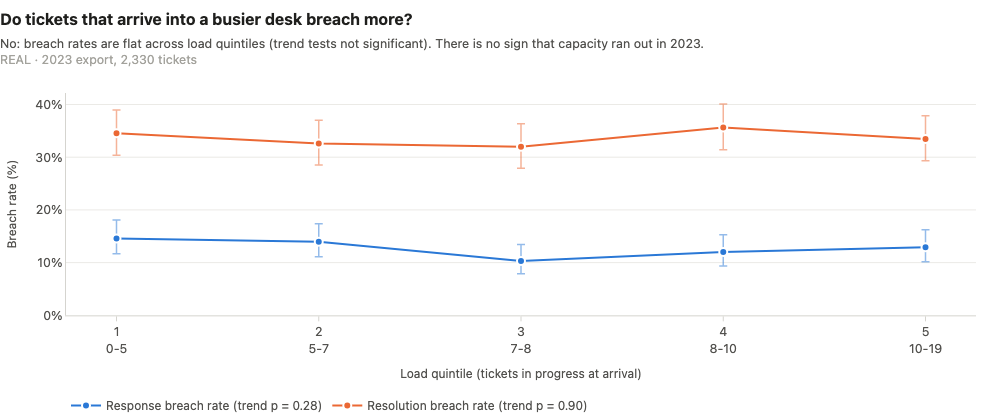

In [11]:
C.fig_load_vs_breach(load, "tickets in progress at arrival")

**What this shows:** each point is a fifth of all tickets, grouped by how many tickets were already in progress
when they arrived (the label gives the range). Both lines are flat: tickets arriving into the busiest fifth breach
no more often than those arriving into the quietest (trend tests p = 0.277 for response,
0.901 for resolution).

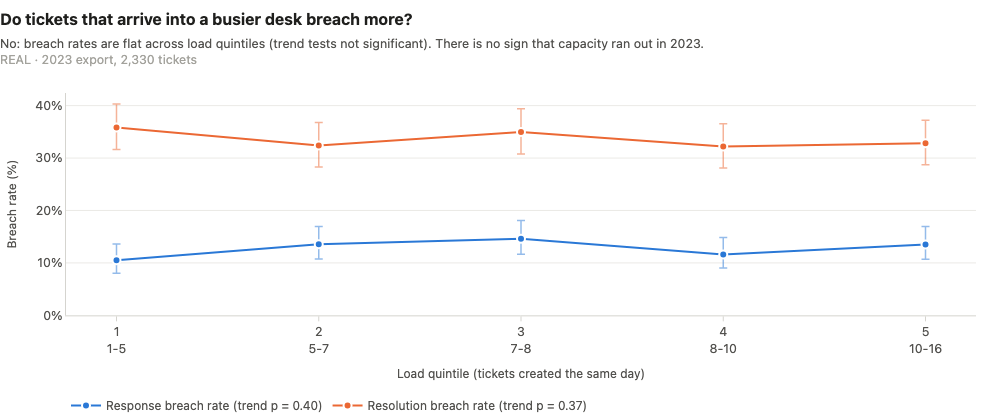

In [12]:
C.fig_load_vs_breach(load, "tickets created the same day")

**What this shows:** the same test with the day's arrivals as the load measure is flat again (p =
0.404 for response, 0.369 for resolution). Across the four tests p ranges from
0.277 to 0.901.

In [13]:
# Do breaches cluster in particular time slots? (support_ops.rca.time_slot_tests, recomputed = cached)
pd.testing.assert_frame_equal(rca.time_slot_tests(fct), slots, check_dtype=False)
slots.round(3)

,slot,sla,chi2,dof,p_value
0,hour of day,response,23.719,23,0.420
1,hour of day,resolution,25.469,23,0.327
2,day of week,response,7.240,6,0.299
3,day of week,resolution,5.677,6,0.460
4,6-hour band,response,6.649,3,0.084
5,6-hour band,resolution,1.273,3,0.736
6,weekday vs weekend,response,0.089,1,0.765
7,weekday vs weekend,resolution,0.102,1,0.750


In [14]:
# Did the team shrink during the year? Named agents owning tickets created in each month (agent = current owner)
agents_per_month = fct.groupby("created_month").agent_name.nunique().rename(lambda d: d.strftime("%b"))
assert (agents_per_month == kn["real_agents"]).all(), "an agent is missing in some month - revisit the text"
agents_per_month.to_frame("named agents").T

created_month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
named agents,8,8,8,8,8,8,8,8,8,8,8,8


If the desk were short in particular slots, breaches would cluster there. They do not: for response SLA, hour
of day p = 0.42, day of week p = 0.299 and weekday vs
weekend p = 0.765; for resolution SLA p runs from 0.327 to
0.750. The closest call is the 6-hour band for response (p = 0.084), not significant
on its own and less so as one of eight slot tests. All 8 named agents own tickets created in every
month, so the data shows no one leaving mid-year. A capacity shortfall would also slow every ticket and grow the
active backlog; instead the median resolution time barely moved (20.3 h →
23.4 h, notebook 02) and active work stayed flat (section 3).

**A trap we avoided: daily correlations.** The obvious test, correlating each day's breach rate with that day's
volume, gives a false signal:

In [15]:
# Why not simply correlate each day's breach rate with that day's volume?
ev = fct[fct.response_sla_met.notna()]
breach, day = (~ev.response_sla_met.astype(bool)).to_numpy(), ev.created_date.to_numpy()


def daily_spearman(b):
    """Spearman correlation between tickets per day and that day's breach rate."""
    g = pd.DataFrame({"day": day, "b": b}).groupby("day").b.agg(["size", "mean"])
    return stats.spearmanr(g["size"], g["mean"]).statistic


r_obs = daily_spearman(breach)
p_naive = stats.spearmanr(daily.tickets, daily.response_breach_rate).pvalue    # the sql/09 daily table
# null world: same tickets on the same days, breach outcomes shuffled (constant risk, no load effect)
rng = np.random.default_rng(0)
null = np.array([daily_spearman(rng.permutation(breach)) for _ in range(500)])
p_perm = (null >= r_obs).mean()
print(f"Daily Spearman r, tickets vs response breach rate: {r_obs:.2f} (naive p = {p_naive:.4f})")
print(f"Same statistic with outcomes shuffled: mean {null.mean():.2f}, "
      f"95% range {np.percentile(null, 2.5):.2f} to {np.percentile(null, 97.5):.2f}")
print(f"Share of shuffles at least as large as observed (permutation p): {p_perm:.2f}")

Daily Spearman r, tickets vs response breach rate: 0.20 (naive p = 0.0001)
Same statistic with outcomes shuffled: mean 0.14, 95% range 0.03 to 0.24
Share of shuffles at least as large as observed (permutation p): 0.11


The naive daily correlation looks highly significant (r = 0.20, p below 0.001). But on a 2-ticket
day the breach rate is usually exactly 0, so quiet days rank low by chance alone. Shuffling breach outcomes across
tickets, a world with constant breach risk and no load effect, produces correlations of a similar size (mean
0.14, up to 0.24), and the observed value is not unusual against them (permutation p =
0.11). That is why the test above works ticket by ticket, not day by day.

### 3. Does the backlog build? Active vs aged tickets [REAL]

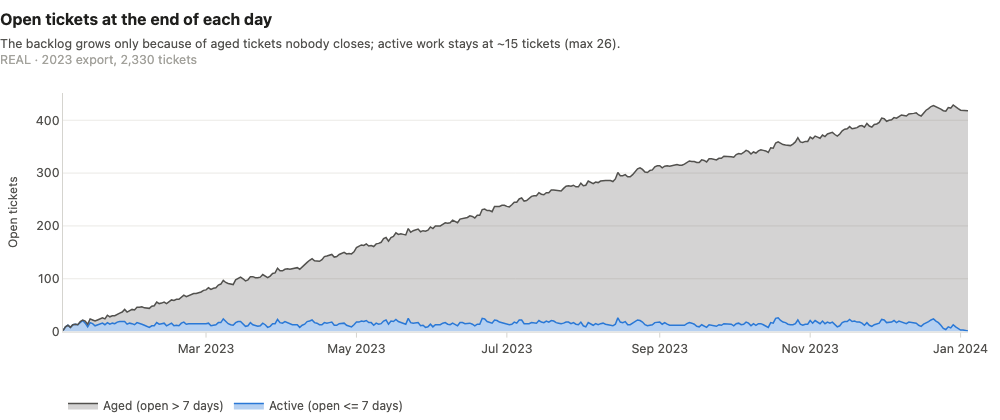

In [16]:
C.fig_backlog(backlog, aged_days)

**What this shows:** grey is tickets open more than 7 days, blue is active work. The total
backlog climbs all year only because aged tickets are never closed; active work stays at about
15 tickets (daily mean 15.1, max 26) with
no upward drift.

In [17]:
# Little's law: L = arrival rate x time in system (time counted as active is capped at the aged threshold)
stale = rca.stale_backlog(fct, backlog, aged_days)
days_active = np.where(fct.is_resolved, np.minimum(fct.resolution_h / 24, aged_days), aged_days)
lam = len(fct) / kn["real_days_in_window"]             # tickets per calendar day (as in rca.stale_backlog)
lam_active = len(fct) / fct.created_date.nunique()     # tickets per day that had tickets
print(f"λ = {lam:.2f} tickets/day, W = {days_active.mean():.2f} days active per ticket "
      f"-> L = λ × W = {stale['littles_law_expected_active']:.1f} active tickets")
print(f"   with λ per day that had tickets ({lam_active:.2f}): L = {lam_active * days_active.mean():.1f}")
print(f"Observed active backlog at day end: mean {stale['active_backlog_mean']:.1f}, max {stale['active_backlog_max']}")

λ = 6.42 tickets/day, W = 2.39 days active per ticket -> L = λ × W = 15.4 active tickets
   with λ per day that had tickets (6.54): L = 15.7
Observed active backlog at day end: mean 15.1, max 26


Little's law predicts 15.4 active tickets from the arrival rate (6.42 a
day) and the time tickets spend active (2.39 days); counting only days that had tickets gives 15.7. We
observe 15.1. Work in progress is what arrivals and resolution times imply: there is no
hidden queue of tickets waiting for capacity.

### 4. Arrival spikes or low throughput? Weekly flows [REAL]

In [18]:
weeks = (backlog.assign(week=pd.to_datetime(backlog.day).dt.to_period("W-SUN").dt.start_time)
                .groupby("week")[["arrivals", "resolutions"]].sum().iloc[1:-1])      # full weeks only
print(f"{len(weeks)} full weeks: {weeks.arrivals.mean():.1f} created vs {weeks.resolutions.mean():.1f} resolved per week "
      f"(gap {(weeks.arrivals - weeks.resolutions).mean():.1f}); week-by-week correlation {weeks.arrivals.corr(weeks.resolutions):.2f}")
print(f"Never-resolved tickets per week of the export: {kn['stale_never_resolved'] / (kn['real_days_in_window'] / 7):.1f}")

51 full weeks: 44.8 created vs 36.8 resolved per week (gap 8.0); week-by-week correlation 0.84
Never-resolved tickets per week of the export: 8.1


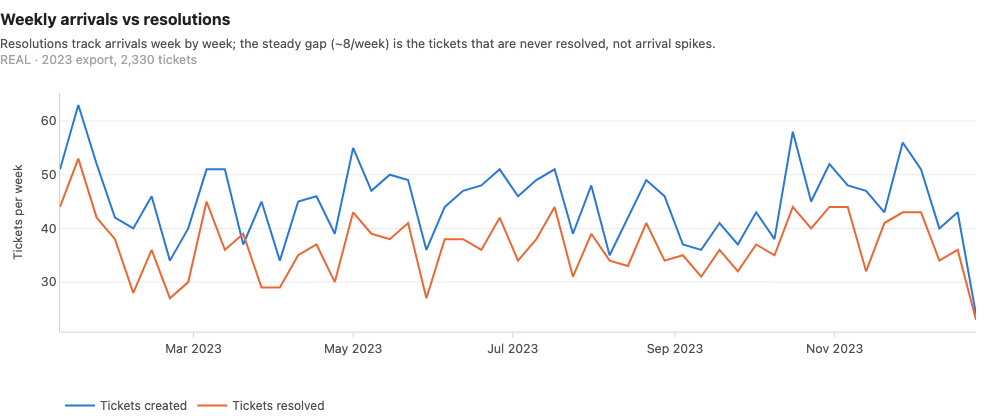

In [19]:
C.fig_weekly_flow(backlog)

**What this shows:** weekly resolutions track weekly arrivals (correlation 0.84); the steady gap of
about 8.0 tickets a week matches the rate at which tickets are left unresolved (8.1 a
week), not arrival spikes. Throughput keeps up with demand; what is missing is closure of a fixed share of
tickets.

### 5. What changed? Outcome of each month's tickets [REAL]

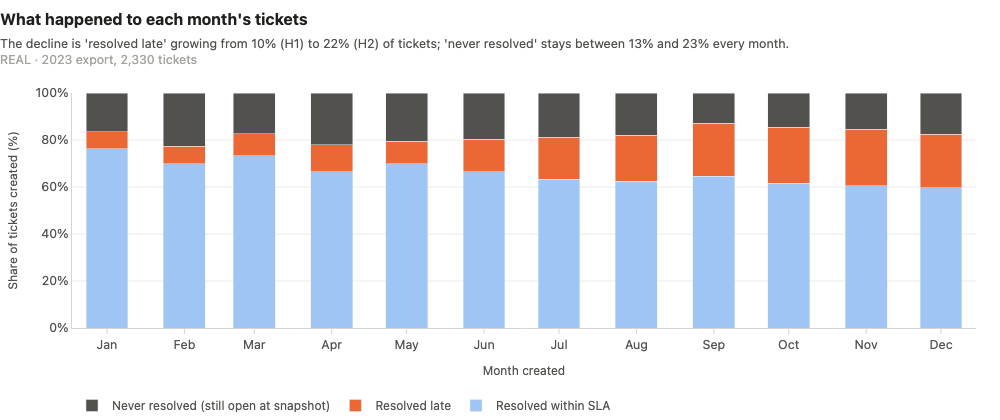

In [20]:
pd.testing.assert_frame_equal(rca.resolution_composition(monthly), comp, check_dtype=False)
C.fig_resolution_composition(comp)

**What this shows:** every month's tickets end in one of three states. On-time resolution shrinks because
"resolved late" grows, from 9.8% of tickets in H1 to 21.8% in H2,
while "never resolved" is roughly constant and slightly lower in H2 (19.6% →
16.3%). Part of the late rise may therefore be tickets that would previously have gone
stale and now close late.

In [21]:
cp = rca.changepoint(comp.set_index("created_month")["share_resolved_late"])
recovery = rca.recovery_scenario(fct)
pd.Series({
    "single step: best month": cp["step_month"],
    "single step: late share before / after": f"{cp['mean_before']:.1%} / {cp['mean_after']:.1%}",
    "single step: R²": f"{cp['step_r2']:.3f}",
    "flat-ramp-flat: ramp from / to": f"{cp['ramp_start']} / {cp['ramp_end']}",
    "flat-ramp-flat: R²": f"{cp['ramp_r2']:.3f}",
    "on-time share H2 if late share went back to H1": f"{recovery['on_time_h2_if_late_back_to_h1']:.1%}",
}, name="resolved-late share, monthly").to_frame()

,"resolved-late share, monthly"
single step: best month,2023-07
single step: late share before / after,9.8% / 21.8%
single step: R²,0.872
flat-ramp-flat: ramp from / to,2023-03 / 2023-10
flat-ramp-flat: R²,0.965
on-time share H2 if late share went back to H1,73.9%


A single step fits best at 2023-07 (late share 9.8%
before, 21.8% after; R² 0.872), but a gradual ramp from
2023-03 to 2023-10 fits better (R² 0.965). With 12 points, and one more
free parameter in the ramp, read this descriptively: the change built up over spring and summer rather than
switching on overnight. It hit every segment alike (notebook 02), which points to something system-wide in the
resolution stage - a process, policy, tooling or dependency change, such as tickets waiting on engineering or on
customers - rather than any team or person. The export has no status history, so it cannot say which. If H2's
resolved-late share went back to the H1 level, on-time resolution would be about
73.9% - a target for the fix, not a forecast.

### 6. The stale backlog: tickets that are never resolved [REAL]

In [22]:
never = fct.resolution_outcome.eq("Unresolved, overdue")
breaches = (~fct.resolution_sla_met).sum()
print(f"Never resolved: {never.sum()} tickets = {never.mean():.1%} of all tickets, "
      f"{never.sum() / breaches:.1%} of all {breaches} resolution breaches")
print(f"Status: {fct[never].status.value_counts().to_dict()}; "
      f"median age at snapshot {fct[never].age_at_snapshot_days.median():.0f} days")
print(f"Share never resolved by half: {never.groupby(fct.created_half).mean().round(3).to_dict()}")
spread = {dim: stats.chi2_contingency(pd.crosstab(fct[dim], never))[1]
          for dim in ["channel", "priority", "topic", "agent_group", "product_group", "agent_name"]}
pd.Series(spread, name="p: does the never-resolved share differ across segments?").round(3).to_frame()

Never resolved: 418 tickets = 17.9% of all tickets, 53.3% of all 784 resolution breaches
Status: {'In progress': 400, 'Open': 18}; median age at snapshot 202 days
Share never resolved by half: {'H1': 0.196, 'H2': 0.163}


,p: does the never-resolved share differ across segments?
channel,0.750
priority,0.397
topic,0.162
agent_group,0.531
product_group,0.102
agent_name,0.199


418 tickets (17.9%) were never resolved:
400 sit "In progress" and 18 never got a first reply. They are
53.3% of all resolution breaches, with a median age of
202 days at the snapshot, so they are unlikely to be live work. They are spread
evenly: no channel, priority, topic, tier, product group or agent stands out (all p ≥ 0.102). This is
a hygiene problem as much as a customer one: genuine tickets need working, abandoned ones need closing with an
outcome code.

### 7. Volume spike or staffing gap? The hourly queue in the planning scenario [SYNTHETIC]

**[SYNTHETIC]** At the export's volume no queue can form, so this section uses the 20×
planning scenario (46,598 synthetic tickets and 202,172 agent touches, built and
validated in notebook 04). The cached simulation replays the synthetic year hour by hour under each roster.
Today's roster is not in the data; the baseline hypothesis is **weekday-weighted** (each day's headcount set by
its new-ticket count), compared here with the **workload-matched** (proposed) roster with the same
23-FTE headcount. The diagnostic: if the queue builds when arrivals spike, it is a volume
problem; if it builds when arrivals are normal but fewer agents are on shift, it is a staffing-pattern problem.

In [23]:
# [SYNTHETIC] hourly view of the simulated year: arrivals, agents on shift and queue, weekday vs weekend
year_h, t0 = 365 * 24, pd.Timestamp("2023-01-01")
hours = pd.DataFrame({"hour_index": np.arange(year_h)})
hours["day_type"] = np.where((t0 + pd.to_timedelta(hours.hour_index, unit="h")).dt.day_of_week >= 5,
                             "weekend", "weekday")
hours["new_tickets"] = np.bincount(((synth_tickets.created_at - t0).dt.total_seconds() // 3600).astype(int),
                                   minlength=year_h)[:year_h]
hours["work_items"] = np.bincount((work_items.arrival_s // 3600).astype(int), minlength=year_h)[:year_h]
sim = sim_hourly[sim_hourly.roster.isin(["by_day", "proposed"]) & (sim_hourly.hour_index < year_h)]
diag = (sim.merge(hours, on="hour_index")
           .groupby(["roster", "day_type"])
           .agg(new_tickets_per_hour=("new_tickets", "mean"), work_items_per_hour=("work_items", "mean"),
                agents_scheduled=("scheduled", "mean"), items_waiting_mean=("queue_len", "mean"),
                items_waiting_max=("queue_len", "max")))
diag.round(2)

new_tickets_per_hour  work_items_per_hour  \
roster   day_type                                              
by_day   weekday                   6.33                25.70   
         weekend                   2.81                16.56   
proposed weekday                   6.33                25.70   
         weekend                   2.81                16.56   

                   agents_scheduled  items_waiting_mean  items_waiting_max  
roster   day_type                                                           
by_day   weekday               6.47                1.08                 47  
         weekend               3.00               11.23                 82  
proposed weekday               6.00                1.59                 39  
         weekend               4.17                1.08                 24

In [24]:
# [SYNTHETIC] where is today's assumed roster short of the hourly requirement?
short = coverage[coverage.scheduled_by_day < coverage.scheduled_required]
print(f"Hours short under today's assumed roster: {len(short)} of 168, by day: {short.dow_name.value_counts().to_dict()}")
print(f"Hours short under the workload-matched roster: {(coverage.scheduled_proposed < coverage.scheduled_required).sum()}")
assert short.dow_name.isin(["Sat", "Sun"]).all(), "gap is not only at weekends - revisit the text"
sim_summary.set_index("roster").loc[["by_day", "proposed"], ["weekly_shifts", "fte", "queue_sl", "max_queue_len"]].round(4)

Hours short under today's assumed roster: 30 of 168, by day: {'Sat': 20, 'Sun': 10}
Hours short under the workload-matched roster: 0


,weekly_shifts,fte,queue_sl,max_queue_len
roster,,,,
by_day,115,23,0.9792,82
proposed,115,23,0.9984,39


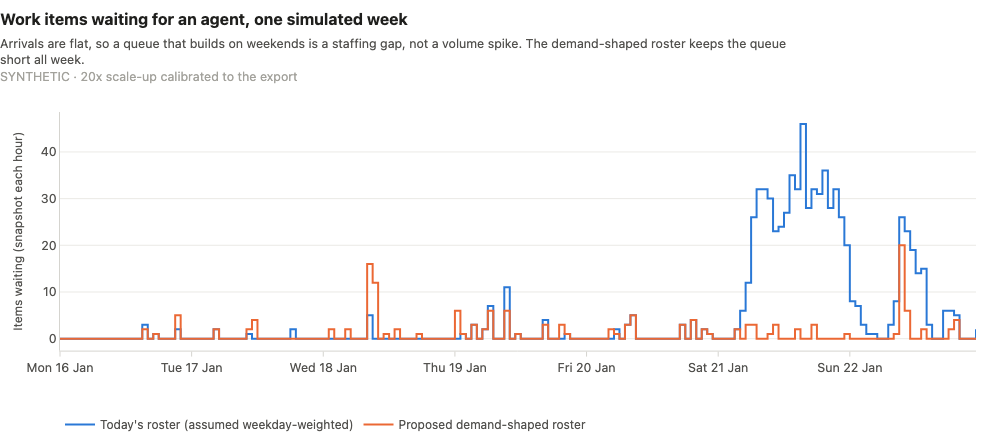

In [25]:
C.fig_sim_queue_week(sim_hourly, demand)

**What this shows:** one simulated week (16-22 January). Under today's assumed weekday-weighted roster the queue
builds on Saturday and Sunday; under the workload-matched roster it stays short, with only brief spikes. The table above gives
the reason across the whole simulated year. Weekend work is *lower* than weekday work (16.6 vs
25.7 agent touches arriving per hour), so the weekend queue is not a volume spike. It appears because the
weekday-weighted roster cuts weekend cover in line with new tickets (3.0 vs 6.5 agents
on shift; 2.8 vs 6.3 new tickets per hour), while the work falls much less, since follow-ups
on the week's tickets continue at weekends. The workload-matched roster moves cover to weekends (4.2
agents on shift vs 6.0 on weekdays) and the average weekend queue falls from 11.2 to
1.1 items. Two conditions apply: today's real roster must actually be weekday-weighted, and weekend
follow-up work must be done when it arises (stress test in notebook 04). The model cannot say whether the real
team is short; the real-data tests above are the evidence on that, and they show no capacity signal.

### Cross-check against `reports/key_numbers.json`

Every headline number above, recomputed in this notebook:

In [26]:
def crosscheck(recomputed):
    """Recomputed numbers must equal reports/key_numbers.json, to the rounding stored there."""
    rows = []
    for key, value in recomputed.items():
        stored, value = kn[key], (value.item() if hasattr(value, "item") else value)
        if isinstance(stored, (int, float)) and not isinstance(stored, bool):
            frac = repr(stored).partition(".")[2]                # 0.0271 -> 4 decimals, 202.0 -> 0
            decimals = 0 if frac in ("", "0") else len(frac)
            tol = max(0.5 * 10 ** -decimals, 1e-5 * abs(stored)) + 1e-9   # stored rounding or float noise
            ok = abs(float(value) - stored) <= tol
        else:
            ok = value == stored
        shown = round(value, 6) if isinstance(value, float) else value
        rows.append({"key": key, "key_numbers.json": stored, "recomputed here": shown, "match": ok})
    out = pd.DataFrame(rows, dtype=object)                       # keep ints as ints in the display
    bad = out[~out["match"].astype(bool)]
    assert bad.empty, bad.to_string()
    return out

In [27]:
recomputed_slots = rca.time_slot_tests(fct).set_index(["slot", "sla"]).p_value
on_time_by_half = fct.groupby("created_half").resolution_outcome.value_counts(normalize=True).unstack()
crosscheck({
    "rca_mix_effect_q1_q4_channel_pp": shares.loc["channel", "mix_pts"],
    "rca_rate_effect_q1_q4_channel_pp": shares.loc["channel", "rate_pts"],
    "rca_mix_effect_q1_q4_topic_pp": shares.loc["topic", "mix_pts"],
    "rca_rate_effect_q1_q4_topic_pp": shares.loc["topic", "rate_pts"],
    "rca_load_trend_p_min": rca.load_vs_sla(fct).trend_p_value.min(),
    "rca_load_trend_p_max": rca.load_vs_sla(fct).trend_p_value.max(),
    "rca_hour_of_day_p_response": recomputed_slots.loc[("hour of day", "response")],
    "rca_day_of_week_p_response": recomputed_slots.loc[("day of week", "response")],
    "rca_weekend_p_response": recomputed_slots.loc[("weekday vs weekend", "response")],
    "active_backlog_mean": run_sql_file("04_backlog_daily.sql").open_active.mean(),
    "active_backlog_max": stale["active_backlog_max"],
    "active_backlog_littles_law": lam * days_active.mean(),
    "stale_never_resolved": never.sum(),
    "stale_share_of_tickets": never.mean(),
    "stale_share_of_resolution_breaches": never.sum() / breaches,
    "stale_median_age_days": fct[never].age_at_snapshot_days.median(),
    "stale_in_progress": (fct[never].status == "In progress").sum(),
    "stale_open_no_response": (fct[never].status == "Open").sum(),
    "rca_on_time_share_h1": on_time_by_half.loc["H1", "Resolved within SLA"],
    "rca_on_time_share_h2": on_time_by_half.loc["H2", "Resolved within SLA"],
    "rca_late_share_h1": on_time_by_half.loc["H1", "Resolved late"],
    "rca_late_share_h2": on_time_by_half.loc["H2", "Resolved late"],
    "rca_never_share_h1": on_time_by_half.loc["H1", "Unresolved, overdue"],
    "rca_never_share_h2": on_time_by_half.loc["H2", "Unresolved, overdue"],
    "rca_on_time_h2_if_late_back_to_h1": recovery["on_time_h2_if_late_back_to_h1"],
    "rca_step_month_late_share": cp["step_month"],
    "rca_late_share_before_step": cp["mean_before"],
    "rca_late_share_after_step": cp["mean_after"],
    "rca_step_r2": cp["step_r2"],
    "rca_ramp_start": cp["ramp_start"],
    "rca_ramp_end": cp["ramp_end"],
    "rca_ramp_r2": cp["ramp_r2"],
    "staff_hours_under_today_by_day": len(short),
    "staff_queue_sl_today_by_day": sim_summary.set_index("roster").loc["by_day", "queue_sl"],
    "staff_queue_sl_proposed": sim_summary.set_index("roster").loc["proposed", "queue_sl"],
    "synth_tickets": len(synth_tickets),
    "synth_work_items": len(work_items),
})

,key,key_numbers.json,recomputed here,match
0,rca_mix_effect_q1_q4_channel_pp,-0.2839,-0.283853,True
1,rca_rate_effect_q1_q4_channel_pp,-12.6544,-12.65443,True
2,rca_mix_effect_q1_q4_topic_pp,0.1046,0.104616,True
3,rca_rate_effect_q1_q4_topic_pp,-13.0429,-13.042898,True
4,rca_load_trend_p_min,0.277,0.277038,True
5,rca_load_trend_p_max,0.901,0.901307,True
6,rca_hour_of_day_p_response,0.42,0.419521,True
7,rca_day_of_week_p_response,0.299,0.299255,True
8,rca_weekend_p_response,0.765,0.765185,True
9,active_backlog_mean,15.1,15.070652,True


## Limitations

- **The cause is not in the data.** The timing of the slowdown is clear; its cause is not. The export has no
  status history (time waiting on the customer, engineering or tier 2), so we cannot say where the slow path is.
  Correlation in time is not causation.
- **Capacity outside the ticket data.** A capacity change the tickets cannot see - time diverted to other work,
  tooling problems, absence - cannot be excluded. The tests show no capacity *signal* in the ticket flow; they
  do not prove capacity was unchanged.
- **Load is measured from timestamps.** "Tickets in progress" counts open tickets, not agent activity; there are
  no handle-time or presence logs.
- **Never-resolved tickets have no outcome code.** Some may have been abandoned by customers rather than left
  unworked; the sweep will tell.
- **Little's law is a rough check.** It assumes a steady state and caps "active" time at 7 days.
- **The changepoint is fitted to 12 points.** Descriptive only; the ramp has one more free parameter than the step.
- **Export provenance.** Resolution clocks ignore weekends and resolution times are capped near 6 days, so the
  shape of the slow tail may not match a production system.
- **Section 7 is a planning scenario.** It depends on the 20× scale factor, assumed
  handle times, how follow-ups are timed and an assumed current roster. It illustrates the diagnostic; it does
  not measure the real desk.

## Recommendations

- **Support team leads - stale-ticket sweep, then a standing policy for tickets open more than 7 days.**
  *Impact:* 418 tickets (17.9%) were never resolved and are
  53.3% of all resolution breaches; working the genuine ones fixes
  customers, closing abandoned ones with an outcome code fixes reporting. *Measure:* never-resolved share of each
  month's tickets (target below 5%); tickets open more than 7 days (target near zero). *Risk:* closing without
  resolving games the metric; require an outcome code and audit a sample of 50 first.
- **Support Director + tier-2 lead, with Ops Analytics - find and reverse the resolution slow path.** *Impact:*
  the resolved-late share rose from 9.8% to 21.8% of all tickets;
  back at the H1 rate, on-time resolution would be near 74% (a target,
  not a forecast). *Measure:* time in each status from the ticket audit log; resolved-late share back to 10% or
  less; 90th-percentile resolution time 48 h or less. *Risk:* the cause may sit outside support (a release,
  tooling, a dependency); it needs status-history data.
- **Support Director - no headcount request this quarter; revisit at a defined trigger.** *Impact:* the 2023
  data shows a process change, not a capacity shortfall, and hiring would mainly buy response SLA, which is not
  the SLA that fell; it avoids about €94k in year one for the hire option
  in the **[SYNTHETIC]** planning scenario. *Measure / trigger:* weekly volume sustained more than
  +25% above 2023, contacts reaching an agent within target below
  90%, or agent utilisation above 85%. *Risk:* volume grows faster than expected; mitigated by the trigger and by
  deflection headroom.
- **WFM / scheduling - check today's real roster, and how weekend follow-ups are handled, before moving
  shifts.** *Impact:* **[SYNTHETIC]** if today's roster is weekday-weighted, the weekend queue is a
  staffing-pattern gap that a re-roster with the same headcount closes (sized in notebook 04). *Measure:* weekend
  vs weekday response SLA and queue wait. *Risk:* the real roster is not in the data; staff preferences on
  weekend shifts.